In [10]:
#Part B- Data Loading and Preparation for Team 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Load the team dataset
team = pd.read_csv('teamstatistics.csv')

In [11]:
#Inspect the dataset
team.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146768 entries, 0 to 146767
Data columns (total 59 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   gameId                   146768 non-null  int64  
 1   gameDateTimeEst          146768 non-null  object 
 2   teamCity                 146752 non-null  object 
 3   teamName                 146766 non-null  object 
 4   teamId                   146768 non-null  int64  
 5   opponentTeamCity         146752 non-null  object 
 6   opponentTeamName         146766 non-null  object 
 7   opponentTeamId           146768 non-null  int64  
 8   home                     146768 non-null  int64  
 9   win                      146766 non-null  float64
 10  teamScore                146768 non-null  int64  
 11  opponentScore            146768 non-null  int64  
 12  assists                  146764 non-null  float64
 13  blocks                   146764 non-null  float64
 14  stea

In [12]:
#Filter teams by the last 5 seasons 2021-2026
team["gameDate"] = pd.to_datetime(team["gameDate"])

team_last_5_seasons = team[
    (team["gameDate"] >= "2021-10-01") &
    (team["gameDate"] < "2026-10-02")
]
team_last_5_seasons.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13888 entries, 206 to 14093
Data columns (total 59 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   gameId                   13888 non-null  int64         
 1   gameDateTimeEst          13888 non-null  object        
 2   teamCity                 13872 non-null  object        
 3   teamName                 13886 non-null  object        
 4   teamId                   13888 non-null  int64         
 5   opponentTeamCity         13872 non-null  object        
 6   opponentTeamName         13886 non-null  object        
 7   opponentTeamId           13888 non-null  int64         
 8   home                     13888 non-null  int64         
 9   win                      13886 non-null  float64       
 10  teamScore                13888 non-null  int64         
 11  opponentScore            13888 non-null  int64         
 12  assists                  13886 non-

In [13]:
#Drop unnecessary columns from the team dataset
team_last_5_seasons = team_last_5_seasons.drop(
    columns=[
        "timesTied", "timeoutsRemaining", "pointsSecondChance", "leadChanges",
        "coachId", "gameSubLabel", "biggestLead", "biggestScoringRun",
        "teamCity", "opponentTeamCity", "pointsFastBreak", "pointsInThePaint", "plusMinusPoints", "seriesGameNumber"
    ],
    errors="ignore"
)

team_last_5_seasons = team_last_5_seasons.loc[
    ~team_last_5_seasons["gameType"].isin(["Playoffs", "Preseason", "All-Star Game", "Summer League", ""])
]

team_last_5_seasons.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13204 entries, 376 to 14093
Data columns (total 45 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   gameId                   13204 non-null  int64         
 1   gameDateTimeEst          13204 non-null  object        
 2   teamName                 13202 non-null  object        
 3   teamId                   13204 non-null  int64         
 4   opponentTeamName         13202 non-null  object        
 5   opponentTeamId           13204 non-null  int64         
 6   home                     13204 non-null  int64         
 7   win                      13202 non-null  float64       
 8   teamScore                13204 non-null  int64         
 9   opponentScore            13204 non-null  int64         
 10  assists                  13202 non-null  float64       
 11  blocks                   13202 non-null  float64       
 12  steals                   13202 non-

In [14]:
#Part C: EDA
#Question 1: How does shooting percentage, rebounds, turnovers, and assists differ between winning and losing teams in the last 5 seasons?

#group by win/loss for each team and find the means 
stats = [
    "fieldGoalsPercentage", "threePointersPercentage", "freeThrowsPercentage",
    "reboundsTotal", "turnovers", "assists"
]

sorted(team_last_5_seasons["teamName"].dropna().unique())
teams_to_remove = ["United", "Jerusalem B.C.", "Loong-Lions", "Phoenix"]

filtered_teams = team_last_5_seasons[
    ~team_last_5_seasons["teamName"].isin(teams_to_remove)
]
team_means = (
    filtered_teams
    .assign(result=filtered_teams["win"].map({1: "Win", 0: "Loss"}))
    .groupby(["teamName", "result"])[stats]
    .mean()
    .unstack("result")
)

team_means

fieldGoalsPercentage           threePointersPercentage  \
result                        Loss       Win                    Loss   
teamName                                                               
76ers                     0.437376  0.490279                0.323795   
Bucks                     0.444958  0.499490                0.345583   
Bulls                     0.452740  0.498830                0.331658   
Cavaliers                 0.455941  0.496087                0.335840   
Celtics                   0.428891  0.488044                0.314725   
Clippers                  0.447720  0.502372                0.331860   
Grizzlies                 0.434848  0.485482                0.332388   
Hawks                     0.446410  0.497882                0.335390   
Heat                      0.438756  0.484261                0.329522   
Hornets                   0.432015  0.492559                0.323456   
Jazz                      0.448989  0.494355                0.330620   
Kings                     0.449408  0.503492                0.323681   
Knicks                    0.438062  0.485612                0.326157   
Lakers                    0.455519  0.506085                0.330202   
Magic                     0.432162  0.487567                0.309704   
Mavericks                 0.446320  0.495681                0.327140   
Nets                      0.438089  0.495672                0.335584   
Nuggets                   0.460747  0.517139                0.331283   
Pacers                    0.455245  0.505220                0.337012   
Pelicans                  0.448206  0.494441                0.327389   
Pistons                   0.442481  0.494144                0.327223   
Raptors                   0.444446  0.483587                0.323751   
Rockets                   0.442624  0.483669                0.322148   
Spurs                     0.448169  0.496436                0.332339   
Suns                      0.450881  0.493992                0.342189   
Thunder                   0.433343  0.494839                0.321852   
Timberwolves              0.447786  0.496693                0.341615   
Trail Blazers             0.432376  0.482933                0.323248   
Warriors                  0.441800  0.488037                0.335456   
Wizards                   0.452086  0.494252                0.331924   

                        freeThrowsPercentage           reboundsTotal  \
result              Win                 Loss       Win          Loss   
teamName                                                               
76ers          0.387154             0.799698  0.824150     39.965854   
Bucks          0.396747             0.732104  0.765632     41.484375   
Bulls          0.388368             0.793528  0.804151     41.796537   
Cavaliers      0.383734             0.758787  0.775806     41.118343   
Celtics        0.393296             0.787645  0.812214     43.681159   
Clippers       0.403820             0.787756  0.811849     41.259067   
Grizzlies      0.372695             0.765393  0.765056     42.245536   
Hawks          0.387564             0.788541  0.795455     42.764706   
Heat           0.387292             0.797627  0.813316     41.521531   
Hornets        0.394764             0.765102  0.788037     42.945255   
Jazz           0.384030             0.775011  0.801729     43.505535   
Kings          0.389604             0.760458  0.787685     41.563025   
Knicks         0.386671             0.762371  0.784776     43.376404   
Lakers         0.378833             0.740236  0.786278     41.778846   
Magic          0.367818             0.770974  0.795488     41.903930   
Mavericks      0.388867             0.752901  0.770562     40.630631   
Nets           0.392068             0.775654  0.795638     40.513619   
Nuggets        0.398347             0.761886  0.784832     42.463855   
Pacers         0.388855             0.767510  0.798882     40.542857   
Pelicans       0.381729             0.771726  0.78553

In [15]:
#Split teams into eastern and western conferences
conference_mapping = {
    "Celtics": "Eastern", "Nets": "Eastern", "Knicks": "Eastern", "76ers": "Eastern", "Raptors": "Eastern",
    "Bulls": "Eastern", "Cavaliers": "Eastern", "Pistons": "Eastern", "Pacers": "Eastern", "Bucks": "Eastern",
    "Heat": "Eastern", "Magic": "Eastern", "Wizards": "Eastern", "Hawks": "Eastern", "Hornets": "Eastern",
    "Warriors": "Western", "Lakers": "Western", "Clippers": "Western", "Suns": "Western", "Kings": "Western",
    "Nuggets": "Western", "Timberwolves": "Western", "Thunder": "Western", "Nuggets": "Western", "Trail Blazers": "Western", "Jazz": "Western",
    "Mavericks": "Western", "Rockets": "Western", "Grizzlies": "Western", "Pelicans": "Western", "Spurs": "Western"
}

eastern_teams = [team for team, conference in conference_mapping.items() if conference == "Eastern"]
western_teams = [team for team, conference in conference_mapping.items() if conference == "Western"]

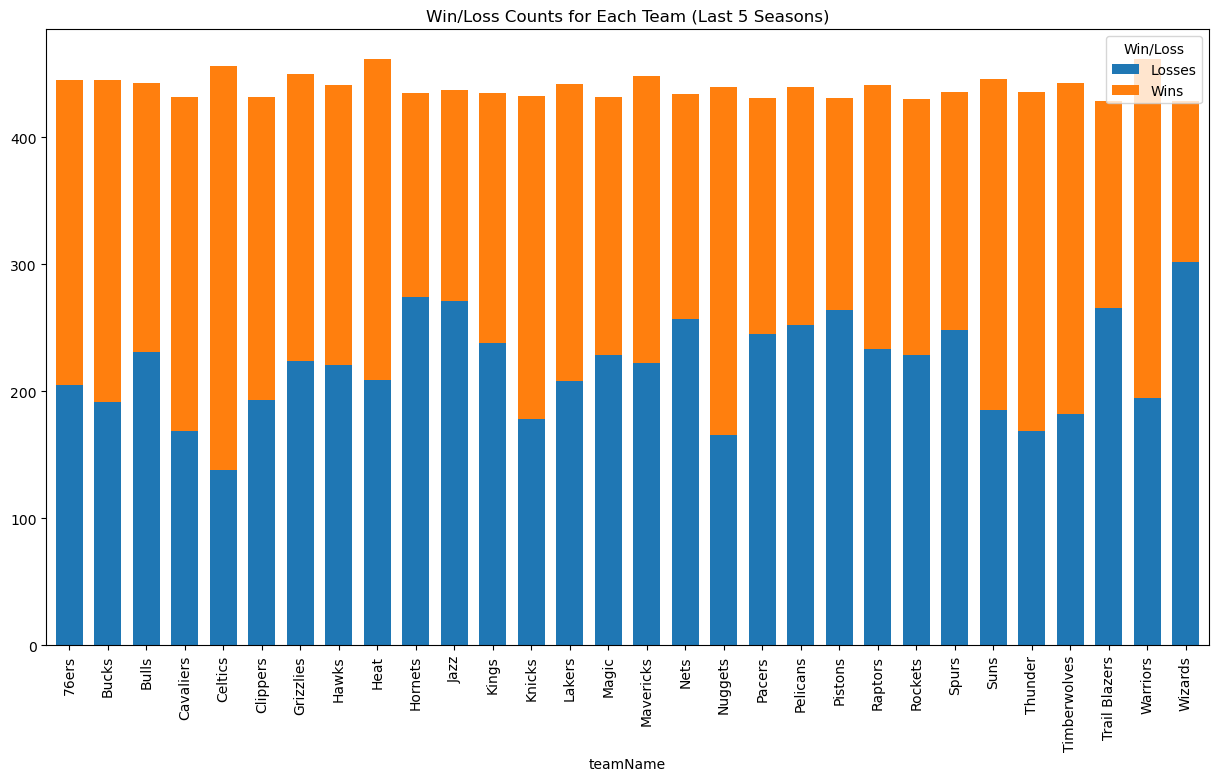

In [16]:
#Visualize the difference in shooting, rebounds, turnovers, and assists between winning and losing 
#Show wins vs losses in a count plot

win_loss_counts = filtered_teams.groupby(["teamName", "win"]).size().unstack(fill_value=0)
ax = win_loss_counts.plot(kind="bar", stacked=True, figsize=(15, 8), width=0.70)

ax.set_title("Win/Loss Counts for Each Team (Last 5 Seasons)")
ax.legend(title="Win/Loss", labels=["Losses", "Wins"])